# Predicting CRISPRi knockdowns in cell lines nobody has perturbed

**Virtual Cell Challenge 2026: our final pipeline, end to end.** Helen Henry (University of Tampere), Nyle Hussain
(University of Glasgow), Kevin Henry.

**The story in one paragraph.** The challenge hands us three human cell lines, D, E and F, as about 18,400
resting ("control") cells each, and a list of 300 genes. For each gene it asks: if you switched this gene down
in this line, what would 400 of its cells look like, RNA molecule by RNA molecule? Nobody has run that
experiment on these lines, and we cannot either. But public experiments have switched many of the same genes
down in *other* cell lines. Our pipeline borrows those measured effects, decides how much to trust each one,
moves them onto the new line, and then draws realistic cells around them. In software terms: **stage 1** predicts a
diff (how much each gene's level changes), **stage 2** renders that diff into concrete samples, and the
grader runs a statistical test on the samples, so the rendering matters as much as the diff.

This notebook is the pipeline that built our final submission, not a reconstruction of it: run in FULL mode,
it rebuilds that file byte for byte from the public data and the challenge's controls.

## How to read this notebook

- **The story is in sections 1 to 15**, in four parts: understand the problem (1, 2), look at the data (3 to 7),
  build the pipeline one measured piece at a time (8 to 12), and the final file (13 to 15). Every section has
  the same shape: **the question**, **the experiment** (code you can rerun), **the figure**, **what we learned**
  (with the number the run printed) and **the playbook lesson**, a rule that holds beyond this challenge. The
  lessons are collected as a checklist at the end.
- **The code is in the package `vccpipe`** next to this notebook (eleven modules, each a readable file), so the
  story starts right after the setup. Each section shows the function it teaches, and the sections explain the
  ideas as they meet them.
- **Every number and figure is computed by this notebook** from the public data and the challenge's controls.
  Scores of earlier versions on the challenge's leaderboard are quoted from our records and marked as quoted.
- **Colours mean the same thing everywhere**: line D blue, E orange, F aqua; the public training screens by
  tissue (blood violet, stem cells green, liver yellow, epithelial magenta); our method in near-black against a
  grey alternative; changes blue for down, red for up.
- **Run modes.** `FAST` (the default) runs the exploration on small public downloads, under an hour on a laptop.
  `FULL` rebuilds the final file (hours; ~80 GB of memory). The official scorer's statistics need a CUDA GPU:
  the sections that score (2, 8, 10, 15) say so and are skipped without one.

## Words we use

| word | meaning |
|---|---|
| **cell line** | a population of human cells grown in the lab from one donor or one tumour, so its cells are near-copies of each other |
| **gene expression, counts** | how many RNA molecules of each gene were captured from one cell: a cell is a vector of 18,533 whole numbers |
| **control cells** | cells given a guide that targets nothing ("non-targeting"): the unperturbed baseline |
| **knockdown, CRISPRi** | switching one gene's expression down: a guide RNA steers a disabled Cas9 protein, fused to a repressor, onto the gene's promoter (the DNA stretch where the gene's reading starts); the DNA itself is not cut |
| **screen, Perturb-seq** | an experiment that knocks down many genes, one per cell, and reads every cell's RNA |
| **log2 fold change** | log2 of (level after the knockdown / level in the controls): +1 doubled, -1 halved, 0 unchanged |
| **profile** | one knockdown's log2 fold change over all genes: the "diff" stage 1 predicts |
| **CPM** | counts per million: a gene's share of the counts, times a million (a level that does not depend on how deeply a cell was read) |
| **UMI, depth** | a molecule's barcode; a cell's depth is how many RNA molecules (UMIs) were counted in it |
| **pseudobulk** | many cells' counts added up into one profile |
| **Wilcoxon rank-sum test** | asks whether one group's values tend to rank above another's; the scorer runs it gene by gene, 400 predicted cells against the line's real controls |
| **called, significant** | a gene whose test p-value, corrected for testing thousands of genes at once (Benjamini-Hochberg), is below 0.05 |
| **10x Flex** | the lab method that measured the challenge's cells; screens measured with other methods see genes somewhat differently |
| **tissue, lineage** | the kind of cell a line comes from: blood, liver, brain, skin lining (epithelial) |
| **pluripotent stem cell (H1, iPSC)** | a cell that can still become any tissue; H1 is an embryonic stem-cell line, KOLF an induced one (iPSC) |
| **p53** | a protein that stops a stressed cell from growing; many cancer lines have lost it, and a line that has it answers some knockdowns differently |

## 0. Setup

`VCC_MODE`: `FAST` (default) runs the exploration on small public downloads; `FULL` rebuilds every reference table
and the final submission (hours, a machine with ~80 GB of memory). Paths: `VCC_NB_DATA` (default `data`) holds the
tables, the challenge's controls, the working files and the saved official scores (`data/scores`).

**Reproducibility is a feature you build first.** The final file is rebuilt here byte for byte, which needs three
things pinned: the library versions, the order of every floating-point sum, and the number of threads the linear
algebra library (BLAS) uses, because a matrix product split over more threads adds its numbers in a different order
and moves the last digit. The thread count is therefore fixed before numpy loads, and each step sets its own.

In [1]:
import os

os.environ.setdefault("OPENBLAS_NUM_THREADS", "6")
os.environ.setdefault("OMP_NUM_THREADS", "6")
os.environ.setdefault("MKL_NUM_THREADS", "6")
os.environ.setdefault("NUMPY_MADVISE_HUGEPAGE", "0")
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")  # library deprecation and empty-slice notices; every check below raises on failure

MODE = os.environ.get("VCC_MODE", "FAST").upper()
assert MODE in ("FAST", "FULL"), MODE
DATA = Path(os.environ.get("VCC_NB_DATA", "data"))
TABLES = Path(os.environ.get("VCC_TABLES", DATA / "tables"))  # the public screens as tables
PHASE = Path(os.environ.get("VCC_PHASE_DIR", DATA / "controls_final"))  # the challenge's final controls
WORK = Path(os.environ.get("VCC_WORK", DATA / "work"))
SUBMIT = os.environ.get("VCC_SUBMIT", "") == "yes"  # never on by default


def gpu_available() -> bool:
    """The official scorer's DE engine (gpudge) needs a CUDA GPU; without one cell-eval2 falls back to another engine
    whose numbers differ. Cells that report the scorer's numbers run only when a GPU is visible."""
    try:
        import torch

        return bool(torch.cuda.is_available())
    except Exception:  # noqa: BLE001
        return False


GPU = gpu_available()
print("mode", MODE, "| GPU for the scorer:", GPU)

mode FULL | GPU for the scorer: True


## The package

The pipeline's code lives in the package `vccpipe` next to this notebook: plain numpy and scipy in eleven documented
modules (unit tests in `tests/`), so the story can start right away. Each section shows the function it teaches
(`show(...)` prints its source).

| module | what it holds | used in |
|---|---|---|
| `inputs` | the public screens as tables; each knockdown's borrowed profile, the significance gate, the neighbour prior | 4, 10, 13 |
| `constants`, `levels` | numbers fitted once on the training screens; the rank test's power from a line's own controls | 11, 13 |
| `combiner` | E, the learned combiner (a small ridge regression across cell types) | 10, 13 |
| `generator` | stage 2: from a predicted change to 400 cells of whole-number counts | 9, 11, 13 |
| `stage1` | stage 1's pieces, ending in each knockdown's targets | 10, 13 |
| `phase` | the entry points: `prepare_phase`, `probe_phase`, `predict_context`, `build_phase` | 13, 15 |
| `harness` | leave one line out, scored by the official scorer | 8, 10, 15 |
| `figures` | the palette and figure helpers | every figure |
| `rebuild`, `fast` | rebuilding the reference tables from public downloads; FAST mode's small inputs | appendix; FAST |

In [2]:
import json

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import norm

from vccpipe import *  # the package's functions, classes and constants, and `show`

## FAST mode's data

In FAST mode the sections below read a small stand-in for the reference tables, built here from public files:
2,000 controls and 100 cells of each of 60 knockdowns per essential-gene line (K562, RPE1, HepG2, Jurkat), read
by byte range; the first 10,000 cells of the 2025 challenge's H1 validation split (FULL uses its training split);
the K562 genome-wide pseudobulk, the pathway screens and DepMap: about 3.5 GB in all. The numbers therefore
differ from a FULL run's; each one printed is computed from these data. KOLF, the other screens and the final
build are FULL only, and section 7's test needs FULL's 18,400 controls: with FAST's 2,000, even its planted
fluctuation is barely found. The reads are polite to the public servers: at most four connections to one
server, and a growing wait (or the server's own Retry-After) whenever one says it is busy. What was read is
kept under the downloads folder, so a rerun reads nothing twice.

In [3]:
if MODE == "FAST":
    TABLES = DATA / "fast"
    if not (TABLES / "phi.npz").exists():
        build_fast_tables(TABLES, Path(os.environ.get("VCC_DOWNLOADS", DATA / "downloads")), PHASE)
    print("FAST tables:", sorted(p.name for p in TABLES.iterdir()))

## 1. What is being asked

**The question.** What exactly goes in, and what must come out? Writing it down first settles what every
later piece has to produce.

**The input**, per cell line: about 18,400 unperturbed control cells, each a vector of whole-number RNA
counts over 18,533 genes, and the list of 300 genes to knock down. **The output**, per line and knockdown:
400 cells of whole-number counts over the same 18,533 genes, as if each gene had been switched down by
CRISPRi (a guide RNA steers a dead Cas9 fused to a repressor onto the gene's promoter; the DNA is not cut).
The model never sees a perturbed cell of the three final lines.

In [4]:
# The code this section is about (from the package):
show(read_phase)

def read_phase(phase_dir: Path):
    """The challenge's input description in `phase_dir`: (manifest, the gene axis, the panel of knockdowns)."""
    manifest = json.loads((phase_dir / "manifest.json").read_text())
    genes = pd.read_csv(phase_dir / "gene_names.csv")["gene_name"].tolist()
    perts = pd.read_csv(phase_dir / "pert_counts.csv")["target_gene"].tolist()
    assert len(genes) == manifest["n_genes"] and len(perts) == manifest["n_constructs"]
    return manifest, genes, perts

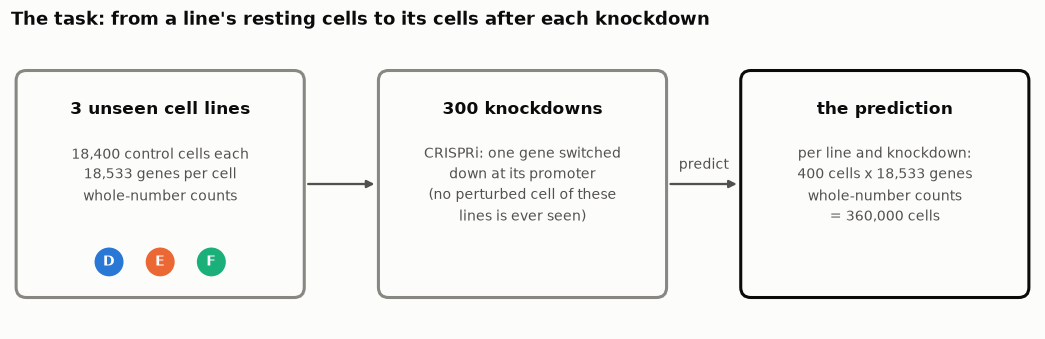

In [5]:
man1, genes1, perts1 = read_phase(PHASE)
fig, ax = plt.subplots(figsize=(12, 3.4))
ax.set_xlim(0, 12), ax.set_ylim(0, 3.4)
ax.axis("off")


def box(x, y, w, h, title, body, colour):
    ax.add_patch(
        mpl.patches.FancyBboxPatch(
            (x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.12", fc=SURFACE, ec=colour, lw=2
        )
    )
    ax.text(x + w / 2, y + h - 0.32, title, ha="center", va="top", fontsize=11, fontweight="bold", color=INK)
    ax.text(x + w / 2, y + h - 0.82, body, ha="center", va="top", fontsize=9, color=INK2, linespacing=1.5)


def arrow(x0, x1, y, label):
    ax.annotate("", xy=(x1, y), xytext=(x0, y), arrowprops={"arrowstyle": "-|>", "color": INK2, "lw": 1.5})
    ax.text((x0 + x1) / 2, y + 0.18, label, ha="center", fontsize=9, color=INK2)


n_ctrl = man1["per_context"][man1["contexts"][0]]["control_cells"] if "per_context" in man1 else None
box(
    0.1,
    0.4,
    3.3,
    2.6,
    f"{len(man1['contexts'])} unseen cell lines",
    f"{n_ctrl:,} control cells each\n{len(genes1):,} genes per cell\nwhole-number counts"
    if n_ctrl
    else f"control cells\n{len(genes1):,} genes per cell",
    MUTED,
)
box(
    4.35,
    0.4,
    3.3,
    2.6,
    f"{len(perts1)} knockdowns",
    "CRISPRi: one gene switched\ndown at its promoter\n(no perturbed cell of these\nlines is ever seen)",
    MUTED,
)
box(
    8.6,
    0.4,
    3.3,
    2.6,
    "the prediction",
    f"per line and knockdown:\n400 cells x {len(genes1):,} genes\nwhole-number counts\n= {len(man1['contexts']) * len(perts1) * 400:,} cells",
    INK,
)
for i, (c, colour) in enumerate(line_colours(man1["contexts"]).items()):  # the lines' colours, used in every figure
    ax.add_patch(mpl.patches.Circle((1.15 + 0.6 * i, 0.78), 0.17, fc=colour, ec="none"))
    ax.text(1.15 + 0.6 * i, 0.78, c, ha="center", va="center", fontsize=9, fontweight="bold", color="#ffffff")
arrow(3.45, 4.3, 1.7, "")
arrow(7.7, 8.55, 1.7, "predict")
ax.set_title("The task: from a line's resting cells to its cells after each knockdown")
plt.show()

**The playbook lesson.** Write down the input and the output, with their exact shapes, before anything else.

## 2. The scorer is the spec

**The question.** What does the official scorer reward? Its six measures (PDS, MSE, NMAE, FID, REACH, JAC)
read two different summaries of the submitted cells: PDS and MSE read each knockdown's pooled profile;
NMAE, FID, REACH and JAC read which genes a per-gene Wilcoxon rank test (400 predicted cells against the
real controls) calls significant, and in which direction. A prediction can be right on average and still
wrong where the test looks.

**The experiment.** A toy line built in the notebook: 300 genes, 2,000 control cells and 8 knockdowns of 200
cells each, every gene a negative binomial; each knockdown moves 20 genes by a log2 fold change of +-1 and
silences its own gene. Four predictions are scored by the official scorer against it, on the challenge's
scale (0 = the control-mean baseline, 1 = a split-half replicate of the real data):
- **replicate**: a fresh draw from the true distribution, what a perfect model would produce;
- **right means, wrong shape**: every cell of a knockdown at that knockdown's true mean (rounded up or down
  at random, so the mean is exact): no cell-to-cell variation;
- **noisy**: the true effects plus a random effect of the same size on 40 other genes;
- **no effect**: control-like cells for every knockdown.

In [6]:
# The code this section is about (from the package):
show(ControlRanks)

class ControlRanks:
    """The scorer's rank-sum test against fixed controls, exactly (average ranks, tie-corrected normal
    approximation, no continuity correction). Per tested gene: the controls' sorted CPM and tie sum."""

    def __init__(self, controls, tested: np.ndarray):
        """`controls`: the line's control cells (cells x genes, counts); `tested`: a mask of the genes tested."""
        C = cpm_dense(controls)
        self.tested = np.asarray(tested, bool)
        self.idx = np.flatnonzero(self.tested)
        self.n2 = C.shape[0]
        self.sorted = np.sort(C[:, self.idx], axis=0).astype(np.float32)
        self.tie_c = np.zeros(len(self.idx))
        for j in range(len(self.idx)):
            _, cnt = np.unique(self.sorted[:, j], return_counts=True)
            self.tie_c[j] = float((cnt.astype(np.float64) ** 3 - cnt).sum())
        self.G = C.shape[1]

    def z(self, cells) -> np.ndarray:
        """Signed z per gene (our cells above the controls -> positive); 0 for untested genes."""
        X = cpm_dense(cells).astype(np.float32)[:, self.idx]
        n1, n2 = X.shape[0], self.n2
        N = n1 + n2
        out = np.zeros(self.G)
        zs = np.empty(len(self.idx))
        for j in range(len(self.idx)):
            x = X[:, j]
            c = self.sorted[:, j]
            lo = np.searchsorted(c, x, side="left")
            hi = np.searchsorted(c, x, side="right")
            xs = np.sort(x)
            olo = np.searchsorted(xs, x, side="left")
            ohi = np.searchsorted(xs, x, side="right")
            below = lo + olo
            ties = (hi - lo) + (ohi - olo)
            r = below + (ties + 1) / 2.0
            U1 = r.sum() - n1 * (n1 + 1) / 2.0
            mu = n1 * n2 / 2.0
            vals, cnt_o = np.unique(x, return_counts=True)
            clo = np.searchsorted(c, vals, side="left")
            chi = np.searchsorted(c, vals, side="right")
            t_c = (chi - clo).astype(np.float64)
            t = t_c + cnt_o
            tie = self.tie_c[j] + ((t**3 - t) - (t_c**3 - t_c)).sum()
            var = n1 * n2 / 12.0 * ((N + 1) - tie / (N * (N - 1)))
            zs[j] = (U1 - mu) / np.sqrt(max(var, 1e-12))
        out[self.idx] = zs
        return out

In [7]:
import shutil

import anndata as ad

rng2 = np.random.default_rng(7)
G2, NC2, NK2, NPC2 = 300, 2000, 8, 200
genes2 = [f"g{i:03d}" for i in range(G2)]
kds2 = genes2[:NK2]  # the knocked-down genes are on the axis, as in the challenge
base2 = np.exp(rng2.normal(0.5, 1.2, G2))  # mean counts per cell
theta2 = 2.0


def nb_cells(mu, n, rng):
    lam = rng.gamma(theta2, mu[None, :] / theta2, size=(n, len(mu)))
    return rng.poisson(lam).astype(np.float32)


true_lfc = {}
for k, g in enumerate(kds2):
    lfc = np.zeros(G2)
    hit = rng2.choice(np.arange(NK2, G2), 20, replace=False)
    lfc[hit] = rng2.choice([-1.0, 1.0], 20)
    lfc[k] = np.log2(0.2)
    true_lfc[g] = lfc


def toy(kind, rng):
    blocks, lab = [nb_cells(base2, NC2, rng)], ["non-targeting"] * NC2
    for g in kds2:
        mu = base2 * 2.0 ** true_lfc[g]
        if kind == "no effect":
            x = nb_cells(base2, NPC2, rng)
        elif kind == "right means, wrong shape":
            lo = np.floor(mu)[None, :]  # the true mean in every cell, rounded at random so the mean is kept
            x = (lo + (rng.random((NPC2, G2)) < (mu - np.floor(mu))[None, :])).astype(np.float32)
        elif kind == "noisy":
            extra = np.zeros(G2)
            extra[rng.choice(np.arange(NK2, G2), 40, replace=False)] = rng.choice([-1.0, 1.0], 40)
            x = nb_cells(mu * 2.0**extra, NPC2, rng)
        else:
            x = nb_cells(mu, NPC2, rng)
        blocks.append(x)
        lab += [g] * NPC2
    return ad.AnnData(
        sp.csr_matrix(np.vstack(blocks)),
        obs=pd.DataFrame({"target_gene": lab}, index=[f"c{i}" for i in range(len(lab))]),
        var=pd.DataFrame(index=genes2),
    )


toy_dir = WORK / "toy_scorer"
shutil.rmtree(toy_dir, ignore_errors=True)
toy_dir.mkdir(parents=True)
real2 = toy(None, rng2)
real2.write_h5ad(toy_dir / "real.h5ad")
KINDS = ["replicate", "right means, wrong shape", "noisy", "no effect"]
cells2 = {kind: toy(kind, np.random.default_rng(100 + i)) for i, kind in enumerate(KINDS)}

In [8]:
if GPU:  # the official scorer's numbers (its DE engine needs a GPU)
    flags = ["--preset", "vcc2026", "--pert-col", "target_gene", "--control", "non-targeting"]
    cell_eval(
        [
            "baseline",
            "-ar",
            str(toy_dir / "real.h5ad"),
            "-o",
            str(toy_dir / "baseline"),
            "--save-pred",
            str(toy_dir / "baseline_pred.h5ad"),
            *flags,
        ],
        toy_dir / "baseline.log",
    )
    cell_eval(
        [
            "prep-real-bundle",
            "--real",
            str(toy_dir / "real.h5ad"),
            "--baseline",
            str(toy_dir / "baseline_pred.h5ad"),
            "-o",
            str(toy_dir / "bundle"),
            *flags,
        ],
        toy_dir / "bundle.log",
    )
    scores2 = {}
    for i, kind in enumerate(KINDS):
        a = cells2[kind]
        f = toy_dir / f"pred_{i}.h5ad"
        a.write_h5ad(f)
        cell_eval(
            ["run", "-ap", str(f), "-ar", str(toy_dir / "real.h5ad"), "-o", str(toy_dir / f"run_{i}"), *flags],
            toy_dir / f"run_{i}.log",
        )
        cell_eval(
            [
                "score",
                "--user-agg",
                str(toy_dir / f"run_{i}" / "agg_results.csv"),
                "--real-bundle",
                str(toy_dir / "bundle"),
                "-o",
                str(toy_dir / f"scored_{i}.csv"),
            ],
            toy_dir / f"score_{i}.log",
        )
        import polars as pl

        df = pl.read_csv(toy_dir / f"scored_{i}.csv")
        v = dict(zip(df["metric"].to_list(), df["from_replicate"].to_list(), strict=True))
        scores2[kind] = {k: float(v[m]) for k, m in SCORER_METRICS.items()}
    print(pd.DataFrame(scores2).round(3))
else:
    print("skipped: the six scores need the scorer's GPU engine")

       replicate  right means, wrong shape  noisy  no effect
pds        1.000                     1.000  1.000      0.537
mse        1.000                     0.997  0.000      0.000
nmae       1.103                     1.161  0.946     -0.138
fid        0.981                     0.529  0.616     -0.653
reach      1.012                     1.012  1.012     -1.167
jac        1.056                     0.060  0.277     -0.097


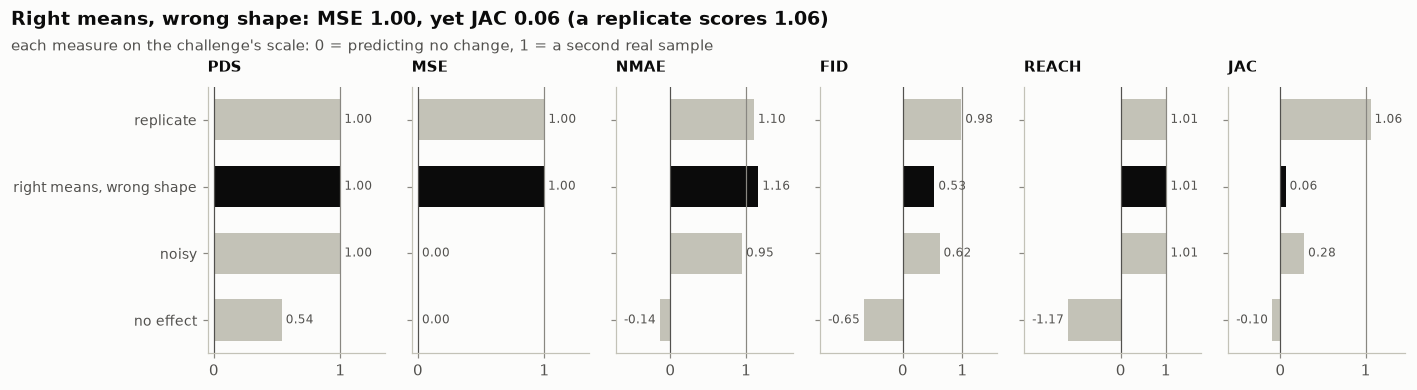

In [9]:
if GPU:
    fig, axes = plt.subplots(1, 6, figsize=(13, 3.2), sharey=True)
    for ax, m in zip(axes, SCORER_METRICS):
        vals = [scores2[k][m] for k in KINDS]
        ax.barh(
            range(len(KINDS)),
            vals,
            color=[INK if k == "right means, wrong shape" else LIGHT for k in KINDS],
            height=0.62,
        )
        ax.axvline(0, color=INK2, lw=0.8)
        ax.axvline(1, color=MUTED, lw=0.8)
        ax.set_title(m.upper(), fontsize=10)
        lo, hi = min(0.0, min(vals)), max(1.0, max(vals))
        ax.set_xlim(lo - (0.45 if lo < 0 else 0.05) * (hi - lo), hi + 0.35 * (hi - lo))
        for i, v in enumerate(vals):
            ax.text(
                v,
                i,
                f" {v:.2f} " if v >= 0 else f"{v:.2f} ",
                va="center",
                ha="left" if v >= 0 else "right",
                fontsize=8,
                color=INK2,
            )
        ax.set_xticks([0, 1], ["0", "1"])
    axes[0].set_yticks(range(len(KINDS)), KINDS, fontsize=9)
    axes[0].invert_yaxis()
    rmws = scores2["right means, wrong shape"]
    fig.tight_layout()
    headline(
        fig,
        f"Right means, wrong shape: MSE {rmws['mse']:.2f}, yet JAC {rmws['jac']:.2f} "
        f"(a replicate scores {scores2['replicate']['jac']:.2f})",
        "each measure on the challenge's scale: 0 = predicting no change, 1 = a second real sample",
    )
    plt.show()

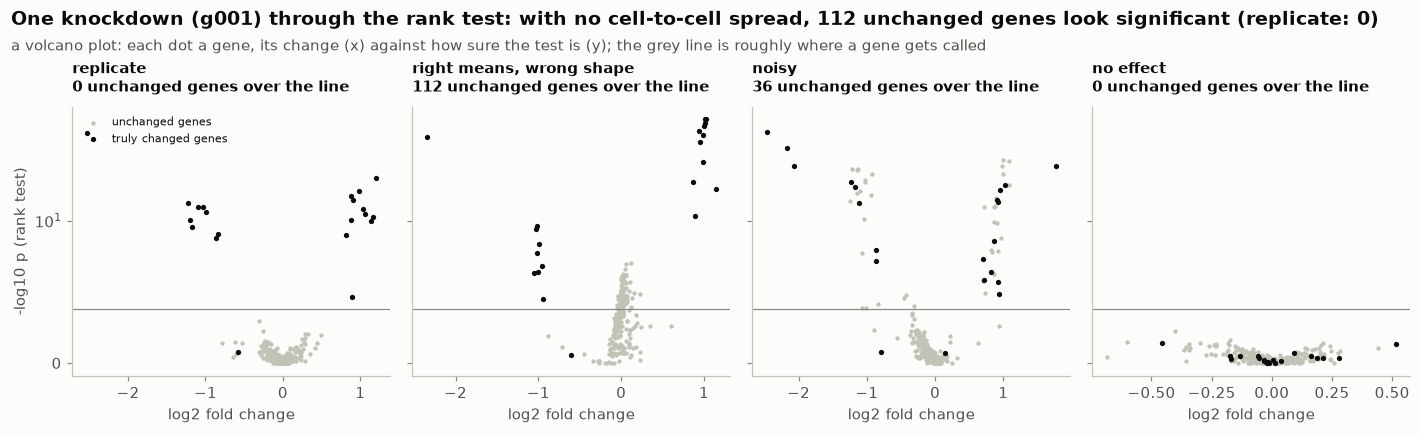

In [10]:
ctrl2 = real2[real2.obs["target_gene"] == "non-targeting"].X
cr2 = ControlRanks(ctrl2, mean_cpm(ctrl2) > 5)
g0 = kds2[1]
fig, axes = plt.subplots(1, len(KINDS), figsize=(13, 3.6), sharey=True)
false_hits = {}
for ax, kind in zip(axes, KINDS):
    a = cells2[kind]
    x = a[a.obs["target_gene"] == g0].X
    z = cr2.z(x)
    lfc = np.log2(np.maximum(mean_cpm(x), 1e-3) / np.maximum(mean_cpm(ctrl2), 1e-3))
    p = 2 * norm.sf(np.abs(z))
    truth = true_lfc[g0] != 0
    ax.scatter(
        lfc[~truth], -np.log10(np.maximum(p[~truth], 1e-300)), s=8, color=LIGHT, linewidths=0, label="unchanged genes"
    )
    ax.scatter(
        lfc[truth], -np.log10(np.maximum(p[truth], 1e-300)), s=12, color=INK, linewidths=0, label="truly changed genes"
    )
    ax.axhline(-np.log10(0.05 / G2), color=MUTED, lw=0.8)  # roughly where the test starts calling a gene
    false_hits[kind] = int(((p < 0.05 / G2) & ~truth).sum())
    ax.set_title(f"{kind}\n{false_hits[kind]} unchanged genes over the line", fontsize=10)
    ax.set_xlabel("log2 fold change")
    ax.set_yscale("symlog", linthresh=10)
axes[0].set_ylabel("-log10 p (rank test)")
axes[0].legend(fontsize=7, frameon=False, loc="upper left")
fig.tight_layout()
headline(
    fig,
    f"One knockdown ({g0}) through the rank test: with no cell-to-cell spread, {false_hits['right means, wrong shape']} "
    f"unchanged genes look significant (replicate: {false_hits['replicate']})",
    "a volcano plot: each dot a gene, its change (x) against how sure the test is (y); the grey line is roughly where a gene gets called",
)
plt.show()

In [11]:
if GPU:
    print(
        f"What we learned: a prediction with the right means but no cell-to-cell spread keeps MSE at "
        f"{scores2['right means, wrong shape']['mse']:.2f} yet scores JAC {scores2['right means, wrong shape']['jac']:.2f} "
        f"(a replicate: {scores2['replicate']['jac']:.2f}); the rank test calls genes that did not change."
    )

What we learned: a prediction with the right means but no cell-to-cell spread keeps MSE at 1.00 yet scores JAC 0.06 (a replicate: 1.06); the rank test calls genes that did not change.


**The playbook lesson.** Build the scorer's intuition before the model: a metric is a program you can test on cases you construct.